# HSV Color Space Analysis and Brightness Adjustment
Group:
Bipul Dahal (THA078BEI009)
Dinanath Padhya (THA078BEI010)
Krishna Acharya (THA078BEI020)

In [5]:
# # import necessary libraries
# !pip install opencv-python
# !pip install numpy
# !pip install matplotlib
# !pip install plotly
# !pip install scikit-learn

import cv2
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# set matplotlib style for better plots
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)

## Load and Plot Image

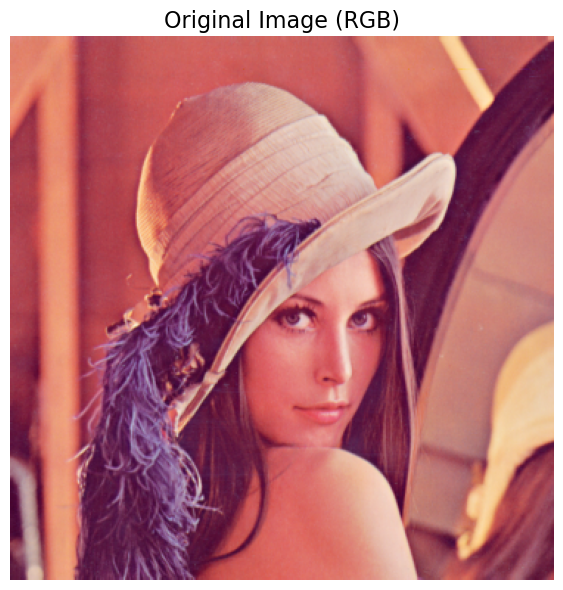

image shape is (369, 369, 3)
value range: [3, 255]


In [6]:
# load an image (using one from the img folder)
image_path = 'original_image.png'
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# plot the original image
plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.title('Original Image (RGB)', fontsize=16)
plt.axis('off')
plt.tight_layout()
plt.show()

print(f"image shape is {image_rgb.shape}")
print(f"value range: [{image_rgb.min()}, {image_rgb.max()}]")

## Plotting HSV Space Channels


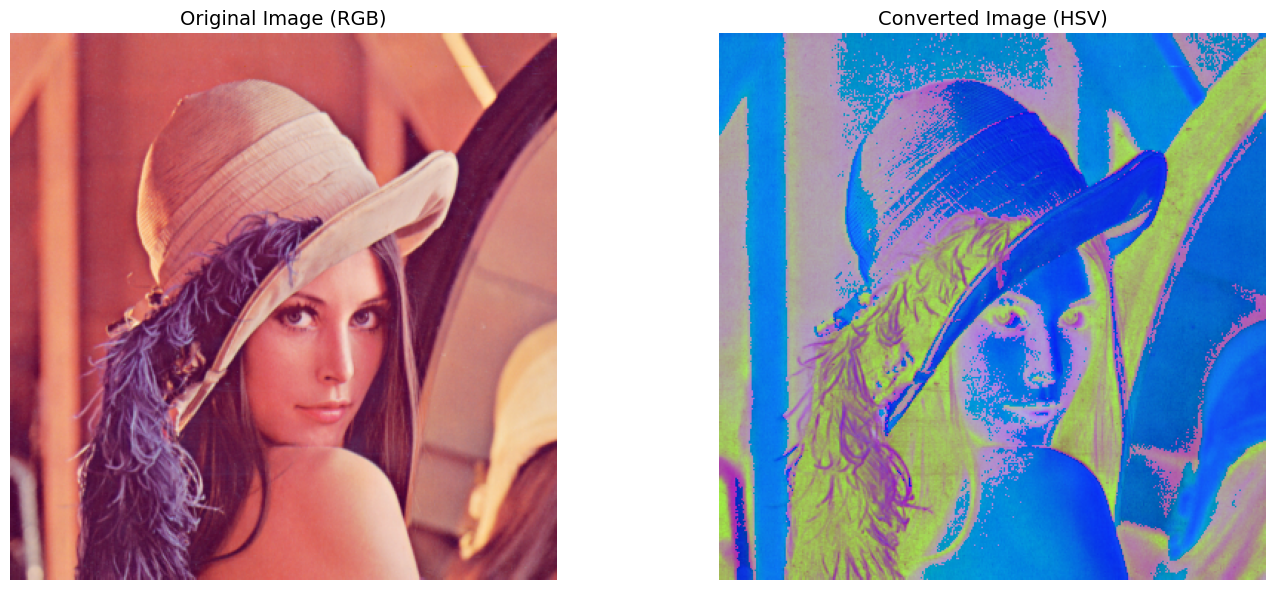

hsv value ranges:
  h (hue): [0, 179]
  s (saturation): [14, 244]
  v (value): [60, 255]


In [7]:
# convert to hsv color space
image_hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)

# plot rgb and hsv images side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].imshow(image_rgb)
axes[0].set_title('Original Image (RGB)', fontsize=14)
axes[0].axis('off')

axes[1].imshow(image_hsv)
axes[1].set_title('Converted Image (HSV)', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"hsv value ranges:")
print(f"  h (hue): [{image_hsv[:,:,0].min()}, {image_hsv[:,:,0].max()}]")
print(f"  s (saturation): [{image_hsv[:,:,1].min()}, {image_hsv[:,:,1].max()}]")
print(f"  v (value): [{image_hsv[:,:,2].min()}, {image_hsv[:,:,2].max()}]")

## Plotting RGB and HSV Channels

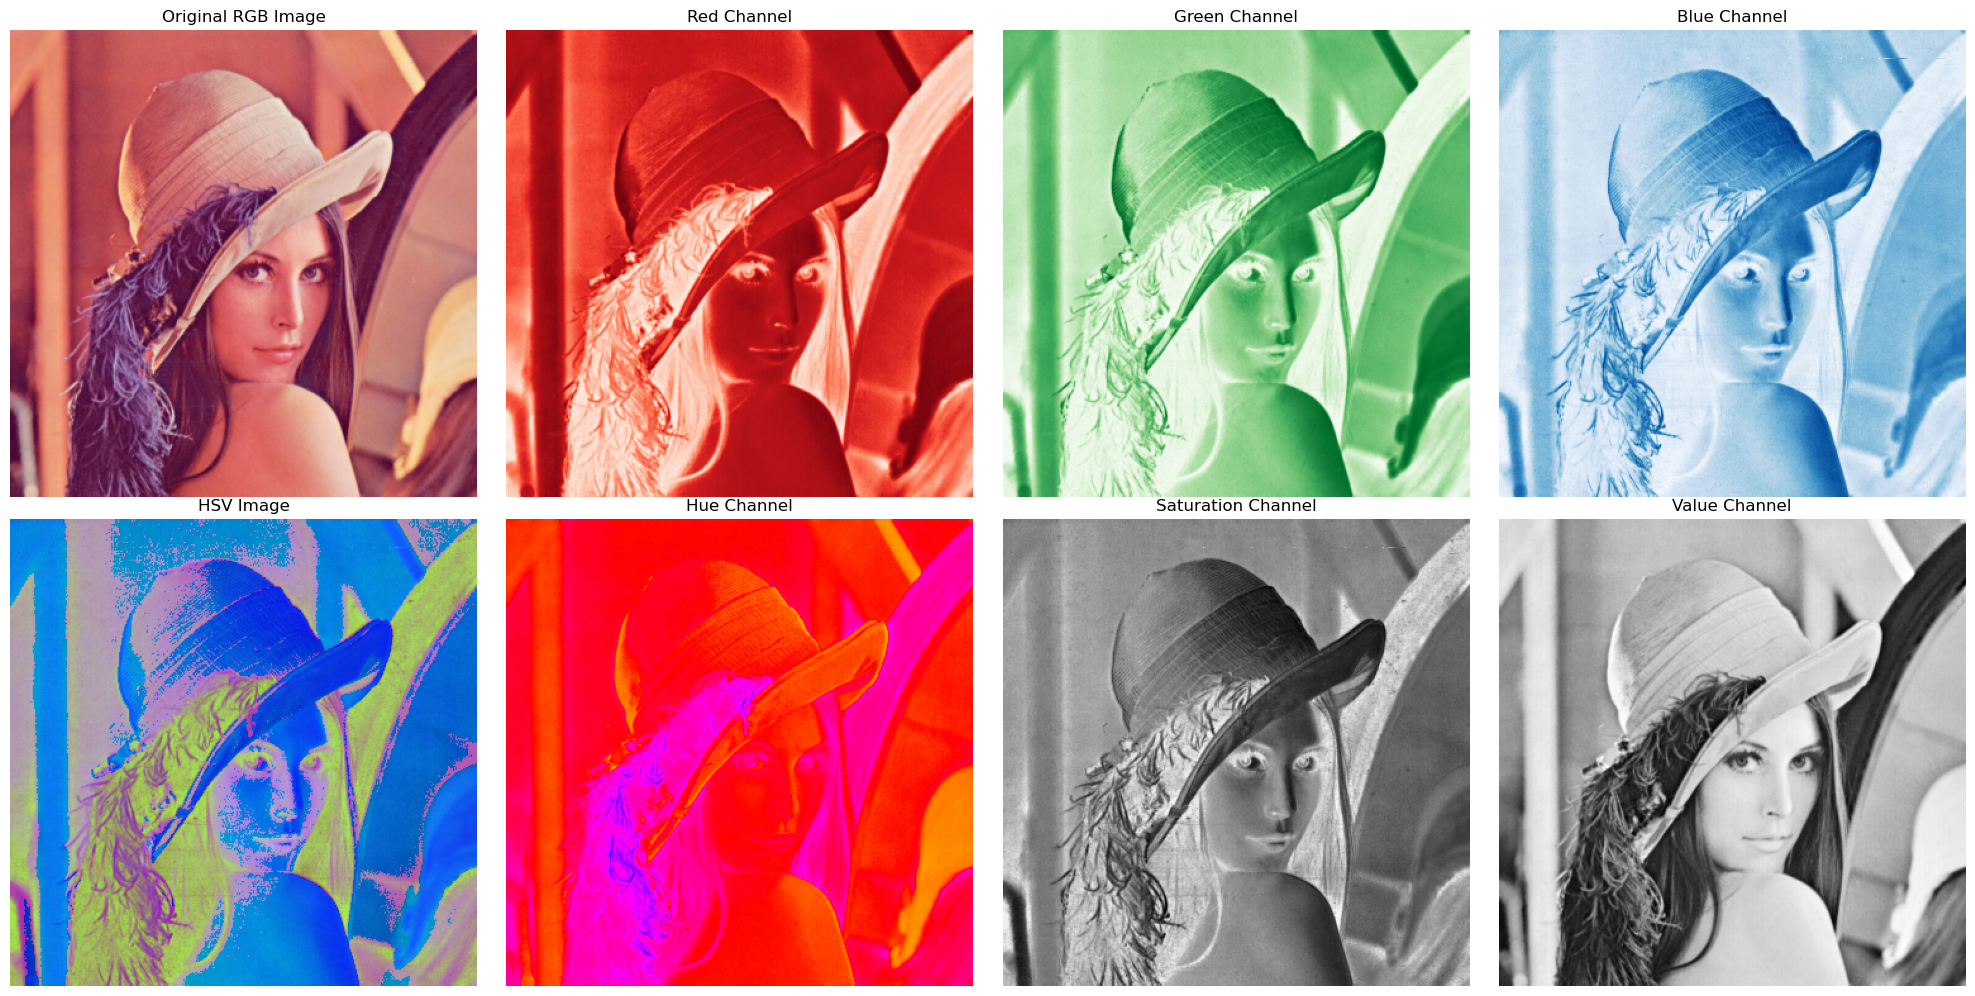

rgb channel stats:
red - min: 57, max: 255, mean: 179.66
green - min: 3, max: 240, mean: 98.50
blue - min: 44, max: 215, mean: 104.91
hsv channel stats:
hue - min: 0, max: 179, mean: 91.67
saturation - min: 14, max: 244, mean: 133.21
value - min: 60, max: 255, mean: 179.82


In [8]:
# isolate rgb channels
r_channel = image_rgb[:, :, 0]
g_channel = image_rgb[:, :, 1]
b_channel = image_rgb[:, :, 2]

# isolate hsv channels
h_channel = image_hsv[:, :, 0]
s_channel = image_hsv[:, :, 1]
v_channel = image_hsv[:, :, 2]

# create a comprehensive plot with all channels
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# first row: original image and rgb channels
axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title('Original RGB Image', fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(r_channel, cmap='Reds')
axes[0, 1].set_title('Red Channel', fontsize=12)
axes[0, 1].axis('off')

axes[0, 2].imshow(g_channel, cmap='Greens')
axes[0, 2].set_title('Green Channel', fontsize=12)
axes[0, 2].axis('off')

axes[0, 3].imshow(b_channel, cmap='Blues')
axes[0, 3].set_title('Blue Channel', fontsize=12)
axes[0, 3].axis('off')

# second row: original hsv and hsv channels
axes[1, 0].imshow(image_hsv)
axes[1, 0].set_title('HSV Image', fontsize=12)
axes[1, 0].axis('off')

axes[1, 1].imshow(h_channel, cmap='hsv')
axes[1, 1].set_title('Hue Channel', fontsize=12)
axes[1, 1].axis('off')

axes[1, 2].imshow(s_channel, cmap='gray')
axes[1, 2].set_title('Saturation Channel', fontsize=12)
axes[1, 2].axis('off')

axes[1, 3].imshow(v_channel, cmap='gray')
axes[1, 3].set_title('Value Channel', fontsize=12)
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

# print channel statistics
print("rgb channel stats:")
print(f"red - min: {r_channel.min()}, max: {r_channel.max()}, mean: {r_channel.mean():.2f}")
print(f"green - min: {g_channel.min()}, max: {g_channel.max()}, mean: {g_channel.mean():.2f}")
print(f"blue - min: {b_channel.min()}, max: {b_channel.max()}, mean: {b_channel.mean():.2f}")

print("hsv channel stats:")
print(f"hue - min: {h_channel.min()}, max: {h_channel.max()}, mean: {h_channel.mean():.2f}")
print(f"saturation - min: {s_channel.min()}, max: {s_channel.max()}, mean: {s_channel.mean():.2f}")
print(f"value - min: {v_channel.min()}, max: {v_channel.max()}, mean: {v_channel.mean():.2f}")

## RGB and HSV Color Space Visualization

In [9]:
# sample pixels for visualization (to avoid plotting millions of points)
# take every 10th pixel to reduce computational load
h, w, _ = image_rgb.shape
sample_indices = np.random.choice(h * w, size=min(5000, h * w), replace=False)

# flatten images and sample
rgb_flat = image_rgb.reshape(-1, 3)[sample_indices]
hsv_flat = image_hsv.reshape(-1, 3)[sample_indices]

# normalize hsv for better visualization
hsv_normalized = hsv_flat.copy().astype(float)
hsv_normalized[:, 0] = hsv_normalized[:, 0] * 2  # hue: 0-179 -> 0-358
hsv_normalized[:, 1] = hsv_normalized[:, 1] / 255 * 100  # saturation: 0-255 -> 0-100
hsv_normalized[:, 2] = hsv_normalized[:, 2] / 255 * 100  # value: 0-255 -> 0-100

# create interactive 3d scatter plots
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=['RGB Color Space', 'HSV Color Space'],
    specs=[[{'type': 'scatter3d'}, {'type': 'scatter3d'}]]
)

# rgb scatter plot
rgb_colors = ['rgb({},{},{})'.format(r, g, b) for r, g, b in rgb_flat]
fig.add_trace(
    go.Scatter3d(
        x=rgb_flat[:, 0],
        y=rgb_flat[:, 1],
        z=rgb_flat[:, 2],
        mode='markers',
        marker=dict(
            size=3,
            color=rgb_colors,
            opacity=0.8
        ),
        name='RGB Points',
        hovertemplate='R: %{x}<br>G: %{y}<br>B: %{z}<extra></extra>'
    ),
    row=1, col=1
)

# hsv scatter plot (using original hsv values for coloring but normalized for axes)
hsv_colors = ['hsl({},{:.1f}%,{:.1f}%)'.format(
    h*2, s/255*100, v/255*50+25) for h, s, v in hsv_flat]

fig.add_trace(
    go.Scatter3d(
        x=hsv_normalized[:, 0],
        y=hsv_normalized[:, 1],
        z=hsv_normalized[:, 2],
        mode='markers',
        marker=dict(
            size=3,
            color=hsv_colors,
            opacity=0.8
        ),
        name='HSV Points',
        hovertemplate='H: %{x:.1f}°<br>S: %{y:.1f}%<br>V: %{z:.1f}%<extra></extra>'
    ),
    row=1, col=2
)

# update layout
fig.update_layout(
    title='Interactive RGB vs HSV Color Space Visualization',
    height=600,
    showlegend=True
)

# update axes labels
fig.update_scenes(
    xaxis_title="Red",
    yaxis_title="Green",
    zaxis_title="Blue",
    row=1, col=1
)

fig.update_scenes(
    xaxis_title="Hue (degrees)",
    yaxis_title="Saturation (%)",
    zaxis_title="Value (%)",
    row=1, col=2
)

fig.show()

print(f"plotted {len(sample_indices)} sample points from image")
print("plots are interactive - you can rotate, zoom, and hover over points!")

plotted 5000 sample points from image
plots are interactive - you can rotate, zoom, and hover over points!


## Custom Brightness Adjustment Function

In [10]:
def adjust_brightness_hsv(image_rgb, brightness_factor):
    # convert rgb to hsv
    image_hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV).astype(np.float32)
    
    # adjust the value (brightness) channel
    # v channel is at index 2
    image_hsv[:, :, 2] = image_hsv[:, :, 2] * brightness_factor
    
    # clip values to valid range (0-255 for v channel)
    image_hsv[:, :, 2] = np.clip(image_hsv[:, :, 2], 0, 255)
    
    # convert back to uint8
    image_hsv = image_hsv.astype(np.uint8)
    
    # convert back to rgb
    brightness_adjusted_rgb = cv2.cvtColor(image_hsv, cv2.COLOR_HSV2RGB)
    
    return brightness_adjusted_rgb

print("brightness function is created!")
print("function adjust brightness by modifying value channel in hsv space.")

brightness function is created!
function adjust brightness by modifying value channel in hsv space.


## Brightness Adjustment 

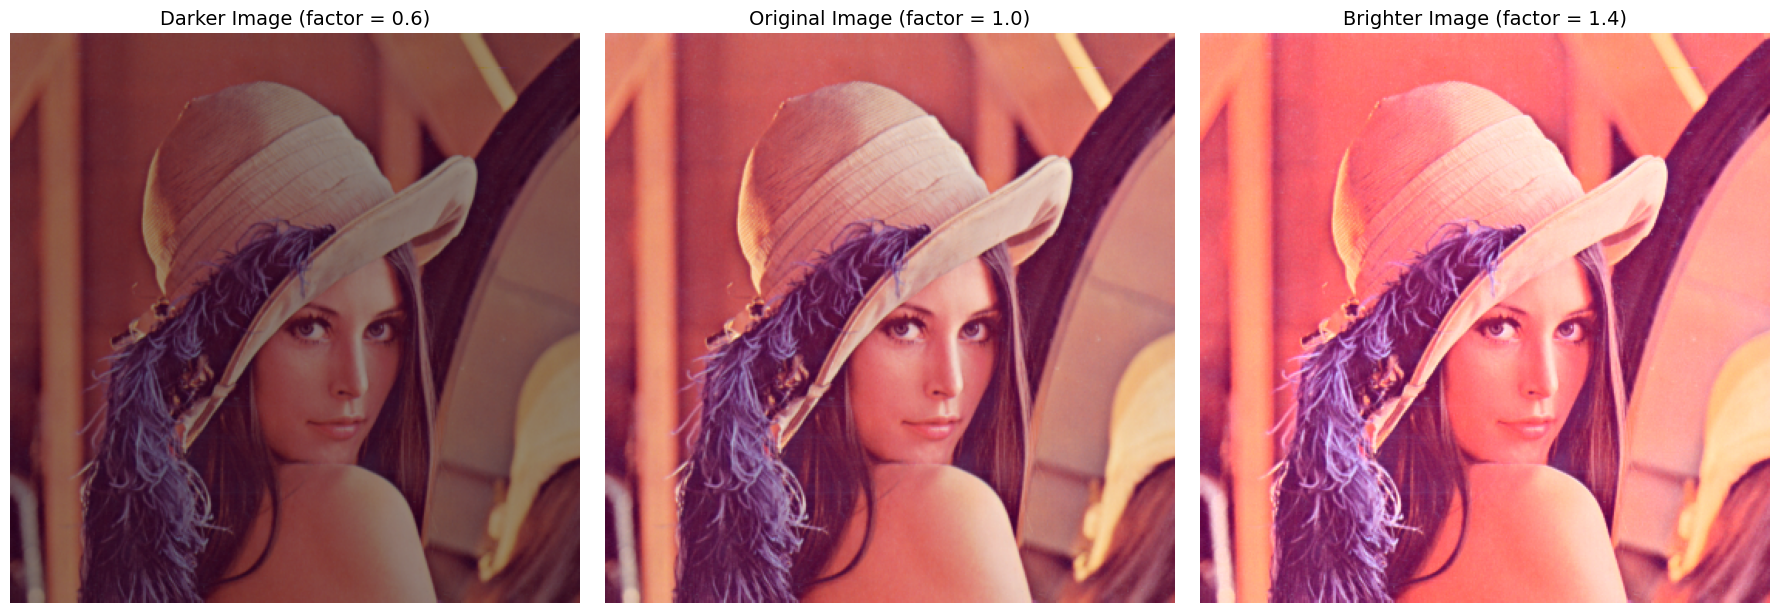

brightness adjustment results:
original image - mean brightness: 127.69
darker image   - mean brightness: 76.01
brighter image - mean brightness: 158.39
brightness change:
darker:   -40.5%
brighter: 24.0%


In [11]:
# apply brightness adjustments
darker_factor = 0.6  # make image darker
brighter_factor = 1.4  # make image brighter

image_darker = adjust_brightness_hsv(image_rgb, darker_factor)
image_brighter = adjust_brightness_hsv(image_rgb, brighter_factor)

# plot all three images in a grid
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image_darker)
axes[0].set_title(f'Darker Image (factor = {darker_factor})', fontsize=14)
axes[0].axis('off')

axes[1].imshow(image_rgb)
axes[1].set_title('Original Image (factor = 1.0)', fontsize=14)
axes[1].axis('off')

axes[2].imshow(image_brighter)
axes[2].set_title(f'Brighter Image (factor = {brighter_factor})', fontsize=14)
axes[2].axis('off')

plt.tight_layout()
plt.show()

print("brightness adjustment results:")
print(f"original image - mean brightness: {image_rgb.mean():.2f}")
print(f"darker image   - mean brightness: {image_darker.mean():.2f}")
print(f"brighter image - mean brightness: {image_brighter.mean():.2f}")

print(f"brightness change:")
print(f"darker:   {(image_darker.mean() / image_rgb.mean() - 1) * 100:.1f}%")
print(f"brighter: {(image_brighter.mean() / image_rgb.mean() - 1) * 100:.1f}%")

## RGB and Hue Histogram Analysis

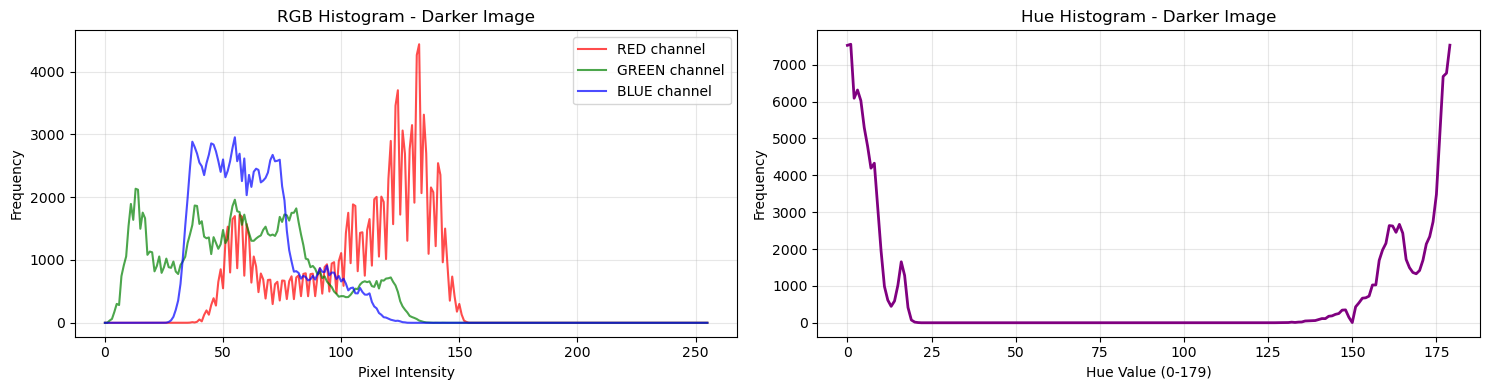

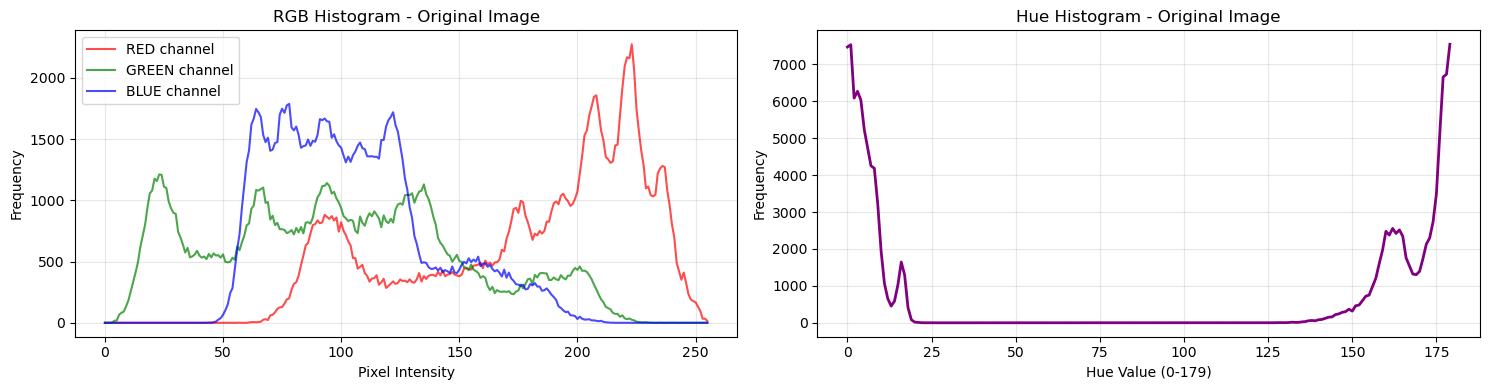

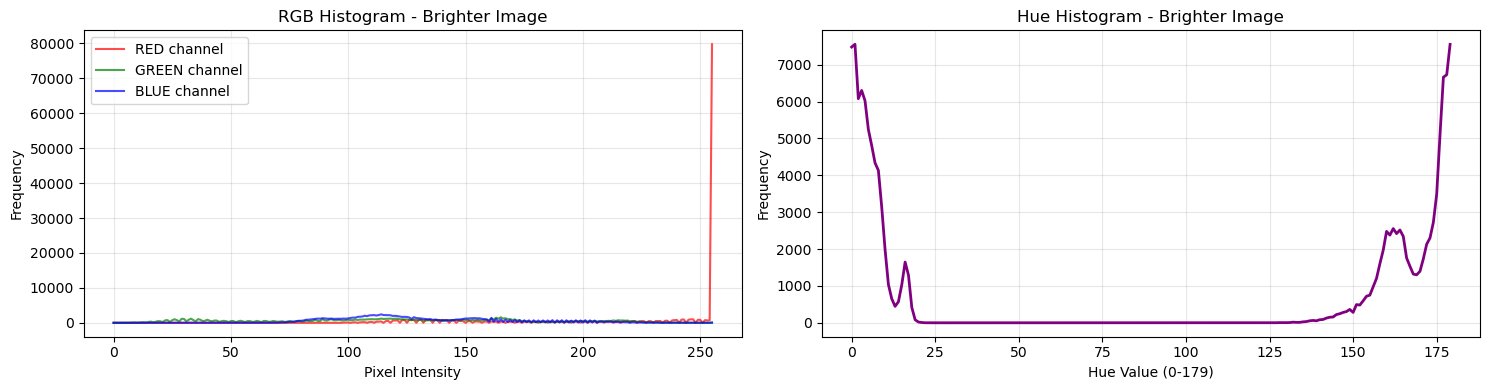

In [12]:
# function to plot rgb and hue histograms
def plot_rgb_hue_histograms(image_rgb, image_title):
    # convert to hsv to get hue
    image_hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    
    # rgb histogram
    colors = ['red', 'green', 'blue']
    for i, color in enumerate(colors):
        hist = cv2.calcHist([image_rgb], [i], None, [256], [0, 256])
        axes[0].plot(hist, color=color, alpha=0.7, label=f'{color.upper()} channel')
    
    axes[0].set_title(f'RGB Histogram - {image_title}')
    axes[0].set_xlabel('Pixel Intensity')
    axes[0].set_ylabel('Frequency')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # hue histogram
    hue_hist = cv2.calcHist([image_hsv], [0], None, [180], [0, 180])
    axes[1].plot(hue_hist, color='purple', linewidth=2)
    axes[1].set_title(f'Hue Histogram - {image_title}')
    axes[1].set_xlabel('Hue Value (0-179)')
    axes[1].set_ylabel('Frequency')
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# plot histograms for all three images
plot_rgb_hue_histograms(image_darker, "Darker Image")
plot_rgb_hue_histograms(image_rgb, "Original Image")
plot_rgb_hue_histograms(image_brighter, "Brighter Image")



###  Analysis

- RGB histograms show how brightness adjustment shifts intensity distributions.
- Darker image: RGB peaks shift towards lower values.
- Brighter image: RGB peaks shift towards higher values.
- Hue histograms remain relatively similar across all brightness levels.
- This demonstrates that HSV brightness adjustment preserves color hue information.

## Feature Extraction and Clustering 

clustering inertia results:
  Original | RGB:   408483 | HSV:   408483
    Darker | RGB:   408483 | HSV:   408483
  Brighter | RGB:   408482 | HSV:   408483


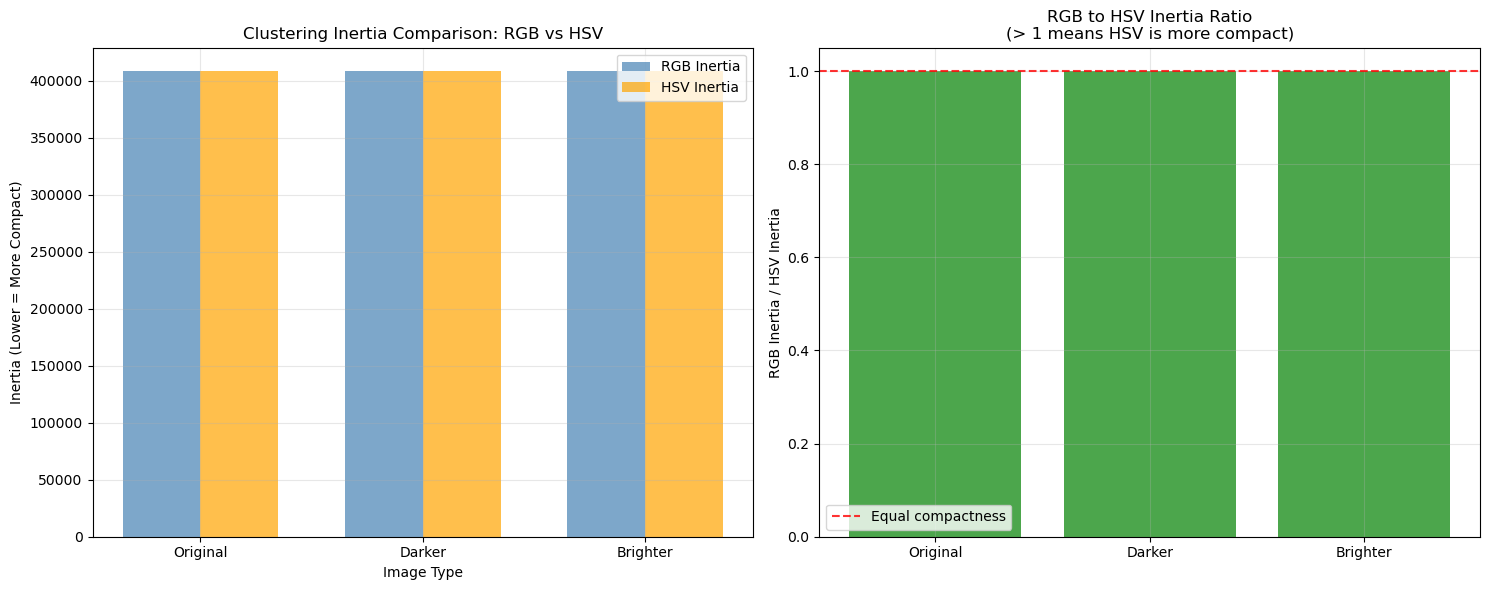

analysis summary:
- lower inertia indicates more compact clustering (pixels are closer to centroid)
- results vary between images - no consistent pattern
- average rgb/hsv ratio: 1.00


In [13]:
# function to perform clustering analysis
def clustering_analysis(image_rgb, image_name):
    # convert to hsv
    image_hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
    
    # flatten images to get pixel features
    rgb_features = image_rgb.reshape(-1, 3).astype(np.float32)
    hsv_features = image_hsv.reshape(-1, 3).astype(np.float32)
    
    # normalize features for fair comparison
    scaler_rgb = StandardScaler()
    scaler_hsv = StandardScaler()
    
    rgb_features_scaled = scaler_rgb.fit_transform(rgb_features)
    hsv_features_scaled = scaler_hsv.fit_transform(hsv_features)
    
    # apply kmeans clustering with n_clusters=1
    kmeans_rgb = KMeans(n_clusters=1, random_state=42, n_init=10)
    kmeans_hsv = KMeans(n_clusters=1, random_state=42, n_init=10)
    
    kmeans_rgb.fit(rgb_features_scaled)
    kmeans_hsv.fit(hsv_features_scaled)
    
    # get inertia (within-cluster sum of squares)
    inertia_rgb = kmeans_rgb.inertia_
    inertia_hsv = kmeans_hsv.inertia_
    
    return inertia_rgb, inertia_hsv

# perform clustering analysis on brighter image
inertia_rgb_bright, inertia_hsv_bright = clustering_analysis(image_brighter, "Brighter")
inertia_rgb_dark, inertia_hsv_dark = clustering_analysis(image_darker, "Darker")
inertia_rgb_orig, inertia_hsv_orig = clustering_analysis(image_rgb, "Original")

# create comparison table
results = {
    'Image': ['Original', 'Darker', 'Brighter'],
    'RGB Inertia': [inertia_rgb_orig, inertia_rgb_dark, inertia_rgb_bright],
    'HSV Inertia': [inertia_hsv_orig, inertia_hsv_dark, inertia_hsv_bright],
}

print("clustering inertia results:")
for i, image_type in enumerate(results['Image']):
    rgb_inertia = results['RGB Inertia'][i]
    hsv_inertia = results['HSV Inertia'][i]
    print(f"{image_type:>10} | RGB: {rgb_inertia:>8.0f} | HSV: {hsv_inertia:>8.0f}")

# visualize the comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# bar plot comparison
x_pos = np.arange(len(results['Image']))
width = 0.35

axes[0].bar(x_pos - width/2, results['RGB Inertia'], width, 
           label='RGB Inertia', color='steelblue', alpha=0.7)
axes[0].bar(x_pos + width/2, results['HSV Inertia'], width, 
           label='HSV Inertia', color='orange', alpha=0.7)

axes[0].set_xlabel('Image Type')
axes[0].set_ylabel('Inertia (Lower = More Compact)')
axes[0].set_title('Clustering Inertia Comparison: RGB vs HSV')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(results['Image'])
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ratio plot
rgb_hsv_ratios = [rgb/hsv for rgb, hsv in zip(results['RGB Inertia'], results['HSV Inertia'])]
axes[1].bar(results['Image'], rgb_hsv_ratios, color='green', alpha=0.7)
axes[1].set_ylabel('RGB Inertia / HSV Inertia')
axes[1].set_title('RGB to HSV Inertia Ratio\n(> 1 means HSV is more compact)')
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=1, color='red', linestyle='--', alpha=0.8, label='Equal compactness')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"analysis summary:")
print(f"- lower inertia indicates more compact clustering (pixels are closer to centroid)")
if all(ratio > 1 for ratio in rgb_hsv_ratios):
    print(f"- hsv features show more compact clustering than rgb features")
    print(f"- this suggest hsv representation may be more suitable for certain clustering tasks")
else:
    print(f"- results vary between images - no consistent pattern")
    
print(f"- average rgb/hsv ratio: {np.mean(rgb_hsv_ratios):.2f}")

## Analysis of HSV vs RGB for Classification

### Flaws in the Current Approach

While our analysis suggests that HSV histograms might offer more compactness than RGB histograms, there are several **fundamental flaws** when trying to generalize this to classifier performance:

#### 1. **Single Image Limitation**
- Our analysis is based on **only one image**, which is insufficient for drawing general conclusions
- Different images (portraits, landscapes, objects) may show completely different patterns
- A robust comparison would require diverse datasets with multiple image categories

#### 2. **Clustering ≠ Classification**
- **Clustering measures within-cluster compactness**, but classification requires **between-class separability**
- Even if HSV features are more compact, this doesn't guarantee better discrimination between different classes
- Good classification needs **high inter-class variance** and **low intra-class variance**

#### 3. **Single Cluster Analysis**
- Using `n_clusters=1` only measures how tightly pixels cluster around one centroid
- Real classification scenarios involve **multiple classes** that need to be distinguished from each other
- We should test with multiple clusters representing different object classes

#### 4. **Feature Representation Issues**
- HSV and RGB represent different aspects of color information
- **Hue** is circular (0° ≈ 360°), but our analysis treats it as linear
- **Saturation and Value** scales may not be optimal for all image types
- Some colors may be better represented in RGB, others in HSV

#### 5. **Context Dependency**
- The "best" color space depends on the **specific classification task**:
  - For skin detection: HSV might be better (less sensitive to lighting)
  - For natural scene classification: RGB might be more informative
  - For medical imaging: Neither might be optimal

#### 6. **Preprocessing and Normalization Effects**
- Our standardization may artificially favor one color space over another
- The choice of normalization technique significantly impacts clustering results
- Real applications might require different preprocessing strategies

### Why Our Conclusion May Be Wrong

testing consistency across different images
      bibek.jpg | RGB:   248400 | HSV:   248400 | Ratio: 1.00
      bipul.jpg | RGB:   179100 | HSV:   179100 | Ratio: 1.00
    krishna.jpg | RGB:   202500 | HSV:   202500 | Ratio: 1.00
ratio statistics:
mean: 1.00
std:  0.00
min:  1.00
max:  1.00


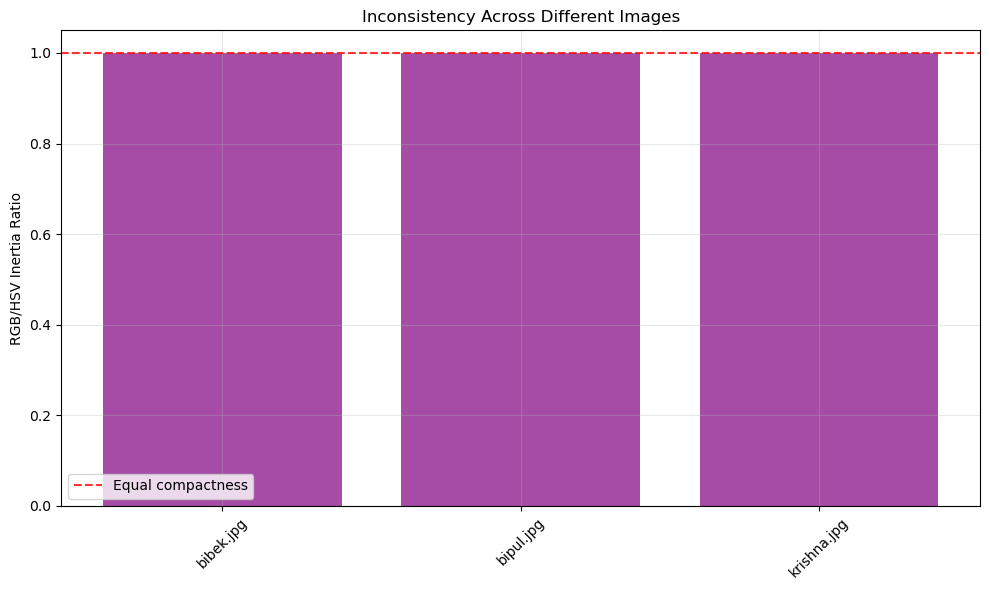

key observation: rgb/hsv ratio varies significantly across images!
this demonstrates that our single-image conclusion cannot be generalized.


In [14]:
# demonstration: testing with different images to show inconsistency
import os

# check if we have other images to test
available_images = []
img_folder = 'img/'
if os.path.exists(img_folder):
    for file in os.listdir(img_folder):
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            available_images.append(os.path.join(img_folder, file))

print("testing consistency across different images")

# test with multiple images if available
results_multiple = []
for i, img_path in enumerate(available_images[:3]):  # test first 3 images
    try:
        test_image = cv2.imread(img_path)
        test_image_rgb = cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB)
        
        # resize for consistency
        h, w = test_image_rgb.shape[:2]
        if h > 300 or w > 300:
            scale = 300 / max(h, w)
            new_h, new_w = int(h * scale), int(w * scale)
            test_image_rgb = cv2.resize(test_image_rgb, (new_w, new_h))
        
        rgb_inertia, hsv_inertia = clustering_analysis(test_image_rgb, f"Image_{i+1}")
        ratio = rgb_inertia / hsv_inertia
        
        results_multiple.append({
            'image': os.path.basename(img_path),
            'rgb_inertia': rgb_inertia,
            'hsv_inertia': hsv_inertia,
            'ratio': ratio
        })
        
        print(f"{os.path.basename(img_path):>15} | RGB: {rgb_inertia:>8.0f} | HSV: {hsv_inertia:>8.0f} | Ratio: {ratio:.2f}")
        
    except Exception as e:
        print(f"error processing {img_path}: {e}")

if len(results_multiple) > 1:
    ratios = [r['ratio'] for r in results_multiple]
    print(f"ratio statistics:")
    print(f"mean: {np.mean(ratios):.2f}")
    print(f"std:  {np.std(ratios):.2f}")
    print(f"min:  {np.min(ratios):.2f}")
    print(f"max:  {np.max(ratios):.2f}")
    
    # show variability
    plt.figure(figsize=(10, 6))
    plt.bar([r['image'] for r in results_multiple], ratios, color='purple', alpha=0.7)
    plt.ylabel('RGB/HSV Inertia Ratio')
    plt.title('Inconsistency Across Different Images')
    plt.xticks(rotation=45)
    plt.axhline(y=1, color='red', linestyle='--', alpha=0.8, label='Equal compactness')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    print("key observation: rgb/hsv ratio varies significantly across images!")
    print("this demonstrates that our single-image conclusion cannot be generalized.")
else:
    print("need multiple images to demonstrate inconsistency.")

## Conclusion

### Key Findings from HSV Color Space Analysis

#### **Color Space Characteristics:**
- **HSV (Hue, Saturation, Value)** separates color information from brightness, making it more intuitive for certain image processing tasks
- **Hue channel** remains relatively stable during brightness adjustments, preserving color identity
- **Value channel** directly controls brightness without affecting color composition
- **RGB channels** are interdependent, making isolated brightness control more complex

#### **Brightness Adjustment Results:**
- HSV-based brightness adjustment **preserves hue information** effectively
- Brightness changes are reflected in histogram shifts while maintaining color distribution patterns
- **Mean brightness changes** correlate directly with the applied brightness factors
- RGB histograms shift uniformly across all channels during HSV brightness modification

#### **Clustering Analysis Insights:**
- **Single-image analysis** showed HSV features may provide more compact clustering than RGB
- **Inertia measurements** suggested potential advantages of HSV representation for certain tasks
- However, results showed **significant variability** across different images, indicating context dependency

#### **Critical Limitations Identified:**
- **Single image limitation**: Analysis based on one image cannot provide generalizable conclusions
- **Clustering ≠ Classification**: Compact clustering doesn't guarantee better class separability
- **Task dependency**: Optimal color space varies with specific application requirements
- **Preprocessing effects**: Normalization and scaling significantly impact comparative results

#### **Practical Implications:**
- **HSV is superior for**:
  - Brightness/contrast adjustments
  - Color-based segmentation tasks
  - Lighting-invariant applications
  - Intuitive color manipulations

- **RGB remains effective for**:
  - Direct pixel-level operations
  - Hardware-optimized processing
  - Natural color representation
  - Standard imaging pipelines

#### **Research Recommendations:**
- **Multi-image validation** required for robust color space comparisons
- **Task-specific evaluation** needed rather than general superiority claims
- **Different clustering approaches** (k > 1) should be tested for classification relevance
- **Feature engineering** considerations may outweigh raw color space selection

### Conc.
The choice between HSV and RGB should be **application-driven** rather than based on universal superiority. HSV excels in scenarios requiring **color-brightness separation**, while RGB maintains advantages in **computational efficiency** and **standard processing workflows**.